<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 4 · Sesión 4: XGBoost: derivación, aplicación a riesgo de crédito e innovaciones recientes</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: objetivo regularizado, árbol reproducido desde cero, early stopping, regularización, monotonicidad, calibración, SHAP e innovaciones 2.0-3.4</div>
</div>

## Objetivos de la sesión (2 horas)

Derivar e implementar **XGBoost** (Chen y Guestrin, *"XGBoost: A Scalable Tree Boosting System"*, KDD 2016, arXiv:1603.02754) y aplicarlo a riesgo de crédito:

1. **Objetivo regularizado**: pérdida + $\Omega(f) = \gamma T + \tfrac{1}{2}\lambda\|w\|^2$ (+ $\alpha\|w\|_1$).
2. **Aproximación de Taylor de segundo orden**: gradientes $g_i$ y Hessianos $h_i$.
3. **Peso óptimo de una hoja** y **ganancia de una partición**: derivación y reproducción exacta de un árbol de XGBoost desde cero.
4. **Búsqueda de particiones**: exacta, aproximada con *weighted quantile sketch*, histogramas y **sparsity-aware** (faltantes).
5. Diferencias con el gradient boosting clásico; regularización con alpha, lambda, gamma, shrinkage y submuestreo.
6. Entrenamiento con **early stopping**, restricciones **monotónicas** y de **interacción**, categóricas nativas, **calibración** y contribuciones SHAP.
7. **Innovaciones recientes de la librería (2023-2026)**: de la versión 2.0 a la 3.4.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 25 min | Derivación del objetivo, pesos y ganancia |
| 2 | 15 min | Reproducir un árbol de XGBoost desde cero |
| 3 | 15 min | Búsqueda de particiones y diseño del sistema |
| 4 | 30 min | XGBoost para PD: early stopping, regularización, restricciones, calibración |
| 5 | 25 min | Innovaciones recientes (2.0 → 3.4) en código |
| 6 | 10 min | Comparación final y ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

import warnings; warnings.filterwarnings("ignore")
import xgboost as xgb, time
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss
print("Versión de XGBoost:", xgb.__version__)
app = pd.read_csv(DATA / "hc_application_sintetico.csv").drop_duplicates()
app["EDAD"] = -app.DAYS_BIRTH / 365.25
app["RCI"] = app.AMT_ANNUITY / (app.AMT_INCOME_TOTAL / 12)
app["ANTIG"] = np.where(app.DAYS_EMPLOYED == 365243, np.nan, -app.DAYS_EMPLOYED / 365.25)       # NaN: XGBoost lo trata de forma nativa
app["PENSIONISTA"] = (app.DAYS_EMPLOYED == 365243).astype(int)
NUM = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD", "RCI", "ANTIG", "PENSIONISTA", "AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_REQ_CREDIT_BUREAU_YEAR", "REGION_RATING_CLIENT", "CNT_CHILDREN"]
CAT = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "CODE_GENDER", "CANAL", "AGENCIA_ID"]
for c in CAT: app[c] = app[c].fillna("Sin dato").astype("category")
FEATS = NUM + CAT
tr = app[app.FECHA_SOLICITUD < "2024-01"]; va = app[(app.FECHA_SOLICITUD >= "2024-01") & (app.FECHA_SOLICITUD < "2025-01")]; te = app[app.FECHA_SOLICITUD >= "2025-01"]
print(f"entrenamiento 2022-2023: {len(tr):,} | validación 2024: {len(va):,} | prueba fuera de tiempo 2025: {len(te):,}")

Versión de XGBoost: 3.4.1


entrenamiento 2022-2023: 30,039 | validación 2024: 15,053 | prueba fuera de tiempo 2025: 14,908


## 1. Derivación (Chen y Guestrin, sección 2)
**Modelo aditivo:** $\hat y_i = \phi(x_i) = \sum_{k=1}^K f_k(x_i)$, con $f_k$ árboles: $f(x) = w_{q(x)}$, donde $q$ asigna cada caso a una de las $T$ hojas y $w \in \mathbb{R}^T$ son los pesos.

**Objetivo regularizado** (ecuación 2): $\mathcal{L}(\phi) = \sum_i l(\hat y_i, y_i) + \sum_k \Omega(f_k)$, con $\Omega(f) = \gamma T + \tfrac{1}{2}\lambda \|w\|^2$.

**Paso $t$ con Taylor de segundo orden** (ecuación 3): con $g_i = \partial_{\hat y} l(y_i, \hat y^{(t-1)})$ y $h_i = \partial^2_{\hat y} l(y_i, \hat y^{(t-1)})$,
$$\tilde{\mathcal{L}}^{(t)} = \sum_i \left[g_i f_t(x_i) + \tfrac{1}{2} h_i f_t^2(x_i)\right] + \gamma T + \tfrac{1}{2}\lambda\sum_j w_j^2 = \sum_{j=1}^T \left[G_j w_j + \tfrac{1}{2}(H_j + \lambda) w_j^2\right] + \gamma T$$
con $G_j = \sum_{i \in I_j} g_i$ y $H_j = \sum_{i \in I_j} h_i$. Es una cuadrática en cada $w_j$:
$$w_j^* = -\frac{G_j}{H_j + \lambda} \qquad \tilde{\mathcal{L}}^{(t)}(q) = -\frac{1}{2}\sum_{j=1}^T \frac{G_j^2}{H_j + \lambda} + \gamma T \quad \text{(ecuaciones 5-6)}$$

**Ganancia de una partición** (ecuación 7): $\text{Gain} = \frac{1}{2}\left[\frac{G_L^2}{H_L + \lambda} + \frac{G_R^2}{H_R + \lambda} - \frac{(G_L + G_R)^2}{H_L + H_R + \lambda}\right] - \gamma$

**Para la pérdida logística** (riesgo de crédito), con $p_i = \sigma(\hat y_i)$: $g_i = p_i - y_i$ y $h_i = p_i(1 - p_i)$, los mismos ingredientes del Newton-Raphson del Módulo 3. En la implementación, **L1** ($\alpha$) aplica *soft-thresholding*: $w_j^* = -\text{sign}(G_j)\max(|G_j| - \alpha, 0)/(H_j + \lambda)$.

| Parámetro | Rol en las ecuaciones |
|---|---|
| `reg_lambda` (λ) | Encoge los pesos: $w^* = -G/(H + \lambda)$ |
| `reg_alpha` (α) | Soft-thresholding de $G$: hojas con poca evidencia → peso 0 |
| `gamma` (γ) | Ganancia mínima para partir: poda |
| `min_child_weight` | $H_j$ mínimo por hoja; en logística, $\sum p(1-p)$: protege hojas con pocos malos |
| `max_delta_step` | Tope a $|w_j|$: útil con clases muy desbalanceadas |
| `learning_rate` (η) | Shrinkage de Friedman: $\hat y^{(t)} = \hat y^{(t-1)} + \eta f_t$ |

## 2. Reproducir un árbol de XGBoost desde cero
Entrenamos **un** árbol de profundidad 1 con $\eta = 1$, $\lambda = 1$, $\gamma = 0$, partiendo de `base_score` = tasa de malos, y lo reproducimos con las ecuaciones anteriores, incluida la **dirección por defecto para faltantes** (algoritmo 3 del paper: se prueba enviar todos los faltantes a la izquierda y a la derecha, y se elige la mejor ganancia).

In [2]:
X3 = app[["EXT_SOURCE_2", "EDAD", "RCI"]].values; y3 = app.TARGET.values; base = y3.mean(); lam = 1.0
m1 = xgb.XGBClassifier(n_estimators=1, max_depth=1, learning_rate=1.0, reg_lambda=lam, gamma=0, min_child_weight=0, base_score=base, tree_method="exact").fit(X3, y3)
print("Árbol de XGBoost:\n" + m1.get_booster().get_dump(with_stats=True)[0])
g = np.full(len(y3), base) - y3; h = np.full(len(y3), base * (1 - base)); G, H = g.sum(), h.sum()
mejor = (-np.inf, None)
for j in range(X3.shape[1]):
    x = X3[:, j]; falt = np.isnan(x)
    o = np.argsort(x[~falt]); xv, gv, hv = x[~falt][o], g[~falt][o], h[~falt][o]
    Gm, Hm = g[falt].sum(), h[falt].sum()
    cg, ch = np.cumsum(gv), np.cumsum(hv)
    valido = np.r_[xv[1:] != xv[:-1], False]
    for direccion in ["derecha", "izquierda"]:
        GL = cg + (Gm if direccion == "izquierda" else 0); HL = ch + (Hm if direccion == "izquierda" else 0); GR, HR = G - GL, H - HL
        gain = GL ** 2 / (HL + lam) + GR ** 2 / (HR + lam) - G ** 2 / (H + lam)
        gain = np.where(valido, gain, -np.inf); k = int(np.argmax(gain))
        if gain[k] > mejor[0]:
            mejor = (gain[k], dict(variable=["EXT_SOURCE_2", "EDAD", "RCI"][j], umbral=(xv[k] + xv[k + 1]) / 2, faltantes=direccion,
                                   w_izq=-GL[k] / (HL[k] + lam), w_der=-GR[k] / (HR[k] + lam), cover_izq=HL[k], cover_der=HR[k]))
print(f"Nuestra implementación: ganancia (sin el factor ½) = {mejor[0]:.3f}")
for k_, v_ in mejor[1].items(): print(f"   {k_}: {v_}")

Árbol de XGBoost:
0:[f0<0.390238523] yes=1,no=2,missing=2,gain=2219.98071,cover=4407.59814
	1:leaf=1.74366617,cover=625.438171
	2:leaf=-0.288726568,cover=3782.15991

Nuestra implementación: ganancia (sin el factor ½) = 2219.980
   variable: EXT_SOURCE_2
   umbral: 0.3902385
   faltantes: derecha
   w_izq: 1.743666005517155
   w_der: -0.28872661016549733
   cover_izq: 625.438203499928
   cover_der: 3782.1601298334053


**Verificación:** misma variable, mismo umbral, misma dirección de los faltantes, misma ganancia (XGBoost reporta la ganancia **sin** el factor ½), mismos pesos de hoja $w^* = -G/(H + \lambda)$ y mismo `cover` (que en logística es $H = \sum p(1-p)$, no el número de casos).

## 3. Búsqueda de particiones y diseño del sistema (secciones 3 y 4 del paper)

| Componente | Idea |
|---|---|
| **Exact greedy** (algoritmo 1) | Enumera todos los cortes; costoso con datos grandes |
| **Aproximado** (algoritmo 2) | Propone cortes candidatos por percentiles y agrega estadísticas por "cubetas" |
| **Weighted quantile sketch** (sección 3.3) | Percentiles ponderados por $h_i$: la pérdida de segundo orden equivale a un MCO ponderado por $h_i$ |
| **Sparsity-aware** (algoritmo 3) | Dirección por defecto aprendida para faltantes y ceros; solo recorre los valores no faltantes |
| **Bloques por columna** (sección 4.1) | Datos preordenados y comprimidos por columna, reutilizados en todas las iteraciones |
| **Cache-aware y out-of-core** (4.2-4.3) | Prefetching, compresión y *sharding* de bloques en disco |
| **hist** (implementación actual) | Histogramas de gradientes con cubetas fijas: el método por defecto desde la versión 2.0 |

In [3]:
tiempos = {}
for tm in ["exact", "approx", "hist"]:
    t0 = time.time(); mm = xgb.XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, tree_method=tm).fit(X3, y3)
    tiempos[tm] = {"segundos": time.time() - t0, "AUC (entrenamiento)": roc_auc_score(y3, mm.predict_proba(X3)[:, 1])}
pd.DataFrame(tiempos).T.style.format({"segundos": "{:.2f}", "AUC (entrenamiento)": "{:.4f}"})

,segundos,AUC (entrenamiento)
exact,2.99,0.7743
approx,2.38,0.7781
hist,0.28,0.7779


### Gradient boosting clásico vs. XGBoost

| Aspecto | Gradient boosting (Friedman, 2001) | XGBoost (2016) |
|---|---|---|
| Aproximación de la pérdida | Primer orden: ajusta el árbol a los pseudo-residuos | **Segundo orden**: $g_i$ y $h_i$ en el criterio de partición |
| Criterio de partición | MCO sobre los residuos; Newton solo para el valor de las hojas | Ganancia derivada del objetivo regularizado |
| Regularización | Shrinkage, submuestreo, tamaño del árbol | **Ω(f) = γT + ½λ‖w‖² + α‖w‖₁**, más shrinkage y submuestreo por filas y columnas |
| Faltantes | Imputación previa | **Dirección por defecto aprendida** |
| Escalabilidad | Secuencial | Paralelismo, sketch ponderado, histogramas, bloques, out-of-core, GPU, distribuido |
| Restricciones | — | Monotónicas, de interacción |

## 4. XGBoost para probabilidades de incumplimiento
### 4.1 Early stopping: elegir el número de árboles en validación

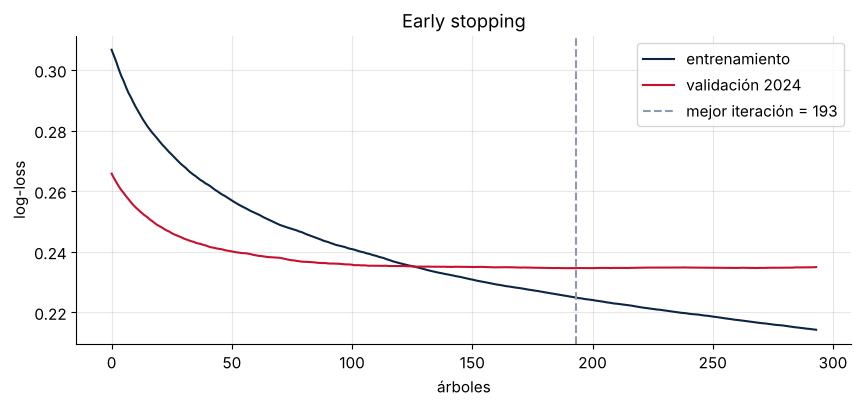

AUC fuera de tiempo 2025: 0.7660 | Gini 0.5319


In [4]:
params = dict(n_estimators=3000, learning_rate=0.03, max_depth=4, min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
              reg_lambda=1.0, reg_alpha=0.0, gamma=0.0, eval_metric="logloss", early_stopping_rounds=100, tree_method="hist")
modelo = xgb.XGBClassifier(**params).fit(tr[FEATS], tr.TARGET, eval_set=[(tr[FEATS], tr.TARGET), (va[FEATS], va.TARGET)], verbose=False)
ev = modelo.evals_result()
plt.figure(figsize=(10, 4))
plt.plot(ev["validation_0"]["logloss"], color=AZUL, label="entrenamiento"); plt.plot(ev["validation_1"]["logloss"], color=ROJO, label="validación 2024")
plt.axvline(modelo.best_iteration, color=GRIS, ls="--", label=f"mejor iteración = {modelo.best_iteration}")
plt.xlabel("árboles"); plt.ylabel("log-loss"); plt.legend(); plt.title("Early stopping"); plt.show()
p_te = modelo.predict_proba(te[FEATS])[:, 1]
print(f"AUC fuera de tiempo 2025: {roc_auc_score(te.TARGET, p_te):.4f} | Gini {2 * roc_auc_score(te.TARGET, p_te) - 1:.4f}")

### 4.2 Efecto de la regularización

In [5]:
def entrenar(**kw):
    p = {**params, **kw}
    m = xgb.XGBClassifier(**p).fit(tr[FEATS], tr.TARGET, eval_set=[(va[FEATS], va.TARGET)], verbose=False)
    pt = m.predict_proba(te[FEATS])[:, 1]
    return {"árboles": m.best_iteration, "logloss_val": min(m.evals_result()["validation_0"]["logloss"]), "AUC_2025": roc_auc_score(te.TARGET, pt)}
grid = {"base (λ=1)": {}, "λ = 20": dict(reg_lambda=20), "α = 5": dict(reg_alpha=5), "γ = 2": dict(gamma=2), "min_child_weight = 50": dict(min_child_weight=50),
        "profundidad 8": dict(max_depth=8), "profundidad 2": dict(max_depth=2), "sin submuestreo": dict(subsample=1.0, colsample_bytree=1.0)}
pd.DataFrame({k: entrenar(**v) for k, v in grid.items()}).T.style.format({"árboles": "{:.0f}", "logloss_val": "{:.5f}", "AUC_2025": "{:.4f}"})

,árboles,logloss_val,AUC_2025
base (λ=1),193,0.23459,0.7660
λ = 20,268,0.23380,0.7679
α = 5,363,0.23225,0.7749
γ = 2,200,0.23467,0.7667
min_child_weight = 50,258,0.23400,0.7695
profundidad 8,101,0.23573,0.7582
profundidad 2,846,0.23152,0.7721
sin submuestreo,173,0.23773,0.7542


### 4.3 Restricciones monotónicas y de interacción
En crédito, un regulador o un comité exigen que **más score externo nunca aumente la PD** y que **más endeudamiento nunca la reduzca**. XGBoost lo garantiza con `monotone_constraints`: una partición solo se acepta si los pesos de las hojas respetan el orden, y los pesos de los descendientes quedan acotados. `interaction_constraints` limita qué variables pueden combinarse en una misma rama.

AUC 2025 sin restricciones: 0.7660 | con monotonicidad: 0.7712


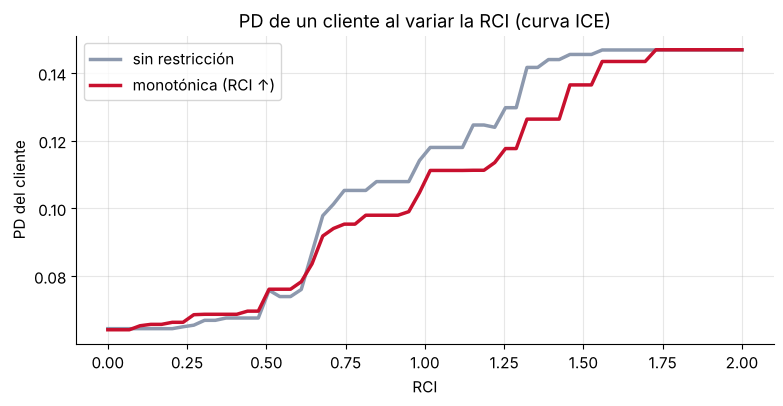

AUC 2025 con restricciones de interacción (scores externos solo entre sí; demográficas solo entre sí): 0.7747


In [6]:
mono = {"EXT_SOURCE_1": -1, "EXT_SOURCE_2": -1, "EXT_SOURCE_3": -1, "RCI": 1, "EDAD": -1}
m_mono = xgb.XGBClassifier(**params, monotone_constraints=mono).fit(tr[FEATS], tr.TARGET, eval_set=[(va[FEATS], va.TARGET)], verbose=False)
p_mono = m_mono.predict_proba(te[FEATS])[:, 1]
print(f"AUC 2025 sin restricciones: {roc_auc_score(te.TARGET, p_te):.4f} | con monotonicidad: {roc_auc_score(te.TARGET, p_mono):.4f}")
fila = te[FEATS].iloc[[0]].copy(); grid_r = np.linspace(0, 2, 60)
fig, ax = plt.subplots(figsize=(9, 4))
for nombre, m, c in [("sin restricción", modelo, GRIS), ("monotónica (RCI ↑)", m_mono, ROJO)]:
    curva = [m.predict_proba(fila.assign(RCI=r))[0, 1] for r in grid_r]; ax.plot(grid_r, curva, color=c, lw=2.5, label=nombre)
ax.set_xlabel("RCI"); ax.set_ylabel("PD del cliente"); ax.legend(); ax.set_title("PD de un cliente al variar la RCI (curva ICE)"); plt.show()
m_int = xgb.XGBClassifier(**params, interaction_constraints=[["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3"], ["EDAD", "RCI", "ANTIG", "PENSIONISTA"]] + [[c] for c in FEATS if c not in ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD", "RCI", "ANTIG", "PENSIONISTA"]])
m_int.fit(tr[FEATS], tr.TARGET, eval_set=[(va[FEATS], va.TARGET)], verbose=False)
print(f"AUC 2025 con restricciones de interacción (scores externos solo entre sí; demográficas solo entre sí): {roc_auc_score(te.TARGET, m_int.predict_proba(te[FEATS])[:, 1]):.4f}")

### 4.4 Calibración de la PD
La pérdida logística produce probabilidades razonablemente calibradas **en la población de entrenamiento**, pero el submuestreo, el early stopping y el cambio de entorno (2025 más benigno) las desplazan. Se verifica y, si hace falta, se recalibra (Módulo 3, sesión 4).

In [7]:
cal = te.FECHA_SOLICITUD < "2025-07"; ev_ = ~cal
logit_te = np.log(p_mono / (1 - p_mono))
platt = LogisticRegression(C=1e6).fit(logit_te[cal].reshape(-1, 1), te.TARGET[cal])
p_platt = platt.predict_proba(logit_te.reshape(-1, 1))[:, 1]
iso = IsotonicRegression(out_of_bounds="clip").fit(p_mono[cal], te.TARGET[cal]); p_iso = iso.predict(p_mono)
filas = []
for nombre, pp in [("XGBoost monotónico", p_mono), ("+ Platt", p_platt), ("+ isotónica", p_iso)]:
    filas.append({"modelo": nombre, "PD media": pp[ev_].mean(), "tasa observada": te.TARGET[ev_].mean(), "Brier": brier_score_loss(te.TARGET[ev_], pp[ev_]),
                  "log-loss": log_loss(te.TARGET[ev_], np.clip(pp[ev_], 1e-6, 1 - 1e-6)), "AUC": roc_auc_score(te.TARGET[ev_], pp[ev_])})
pd.DataFrame(filas).set_index("modelo").style.format({"PD media": "{:.2%}", "tasa observada": "{:.2%}", "Brier": "{:.5f}", "log-loss": "{:.5f}", "AUC": "{:.4f}"})

,PD media,tasa observada,Brier,log-loss,AUC
modelo,,,,,
XGBoost monotónico,8.11%,5.91%,0.05108,0.19472,0.7846
+ Platt,5.62%,5.91%,0.05031,0.19126,0.7846
+ isotónica,5.61%,5.91%,0.05045,0.19522,0.7833


### 4.5 Contribuciones por cliente (SHAP nativo)
`pred_contribs=True` descompone el log-odds de cada cliente en aportes por variable que **suman exactamente** la predicción (TreeSHAP). Es la base de las razones de decisión para modelos de árboles; lo profundizaremos en el Módulo 7.

In [8]:
dm = xgb.DMatrix(te[FEATS].head(3), enable_categorical=True)
contrib = m_mono.get_booster().predict(dm, pred_contribs=True)
tabla = pd.DataFrame(contrib, columns=FEATS + ["sesgo (base)"]).T
tabla.columns = [f"cliente {i + 1}" for i in range(3)]
print("Suma de contribuciones = log-odds predicho:", np.allclose(contrib.sum(1), m_mono.get_booster().predict(dm, output_margin=True), atol=1e-4))
tabla.loc[tabla.abs().max(axis=1).sort_values(ascending=False).index[:8]].style.format("{:+.3f}")

Suma de contribuciones = log-odds predicho: True


,cliente 1,cliente 2,cliente 3
sesgo (base),-2.284,-2.284,-2.284
EXT_SOURCE_2,+0.026,-1.014,-0.049
AGENCIA_ID,+0.058,+0.253,+0.323
NAME_EDUCATION_TYPE,-0.289,-0.159,-0.305
REGION_RATING_CLIENT,-0.040,+0.072,-0.305
OCCUPATION_TYPE,-0.102,-0.252,-0.062
ANTIG,+0.013,-0.178,-0.153
EDAD,-0.030,-0.140,-0.150


## 5. Innovaciones recientes de XGBoost (2023-2026)

| Versión (fecha) | Innovación | Relevancia para riesgo de crédito |
|---|---|---|
| **2.0** (sep. 2023) | Parámetro unificado `device` (cpu/cuda); `hist` por defecto; **árboles multi-salida** (`multi_strategy="multi_output_tree"`); **regresión por cuantiles** (`reg:quantileerror`); intercepto estimado automáticamente; renovación de learning to rank | Un solo código para CPU y GPU; cuantiles para LGD, EAD o ingresos |
| **2.1** (jun. 2024) | Entrada nativa de DataFrames (pandas, Arrow); modelos en UBJSON por defecto; avances en multi-salida y aprendizaje federado | Menos conversiones y memoria; despliegue más robusto |
| **3.0** (feb. 2025) | `ExtMemQuantileDMatrix`: **memoria externa** rápida en CPU y GPU, también distribuida; sketch multinivel; `Booster.reset()` | Entrenar con carteras que no caben en memoria |
| **3.1** (sep. 2025) | **Re-codificador de categorías**: el modelo guarda las categorías y re-codifica en inferencia; soporte categórico deja de ser experimental; intercepto vectorial multi-salida; se eliminan `gpu_hist` y `gpu_id` | Consistencia entre entrenamiento y producción (un error clásico de MLOps) |
| **3.2** (feb. 2026) | Árboles **vector-leaf** ampliados (todas las regresiones, incluida cuantil); muestreo basado en gradientes en CPU | Varios cuantiles o varios objetivos en un solo árbol |
| **3.3** (jun. 2026) | **Regresión de expectiles** (`reg:expectileerror`); **categóricas activadas por defecto**; TreeSHAP reescrito (*QuadratureTreeSHAP*): más estable y rápido; RNG serializado para muestreo **reproducible**; `gblinear` deprecado | Reproducibilidad (auditoría); explicaciones más estables |
| **3.4** (ago. 2026) | Vector-leaf completo (categóricas, DART, **restricciones monotónicas y de interacción**); hojas de cuantil y MAE por aproximaciones suaves; envoltorios de random forest deprecados | Modelos multi-salida que cumplen restricciones regulatorias |

Fuentes: notas de versión en `xgboost.readthedocs.io/en/stable/changes`. A continuación, varias en código con la versión instalada.

In [9]:
# (a) Re-codificador de categorías (3.1) y categóricas por defecto (3.3): mismo resultado aunque cambie el orden de las categorías en producción
prod = te[FEATS].head(5).copy()
prod["CANAL"] = prod.CANAL.cat.reorder_categories(list(reversed(prod.CANAL.cat.categories)))
print("PD con categorías en el orden de entrenamiento:", m_mono.predict_proba(te[FEATS].head(5))[:, 1].round(4))
print("PD con categorías reordenadas en producción:   ", m_mono.predict_proba(prod)[:, 1].round(4))
print("enable_categorical por defecto:", xgb.XGBClassifier().get_params()["enable_categorical"], "| device:", modelo.get_params().get("device"))

PD con categorías en el orden de entrenamiento: [0.0697 0.0267 0.0583 0.106  0.0161]
PD con categorías reordenadas en producción:    [0.0697 0.0267 0.0583 0.106  0.0161]
enable_categorical por defecto: True | device: None


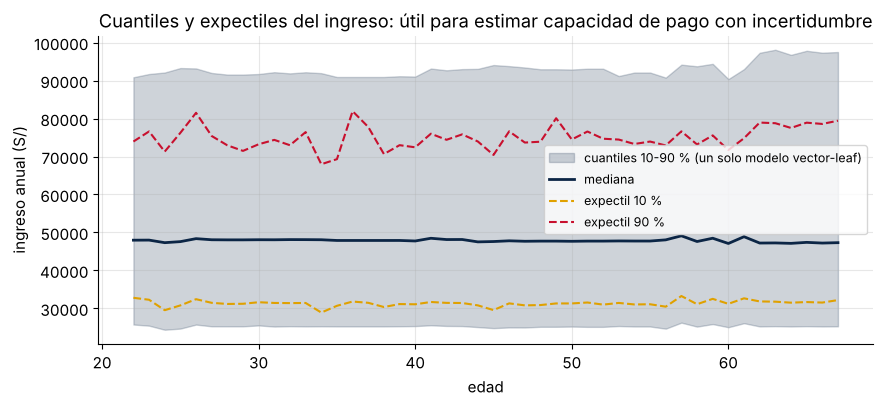

In [10]:
# (b) Regresión por cuantiles (2.0) con un árbol vector-leaf (3.2) y expectiles (3.3): ingreso esperado según edad
Xq = app[["EDAD", "PENSIONISTA"]]; yq = np.log(app.AMT_INCOME_TOTAL)
q = xgb.XGBRegressor(objective="reg:quantileerror", quantile_alpha=np.array([0.1, 0.5, 0.9]), multi_strategy="multi_output_tree", tree_method="hist", n_estimators=100, max_depth=3).fit(Xq, yq)
e = xgb.XGBRegressor(objective="reg:expectileerror", expectile_alpha=np.array([0.1, 0.9]), n_estimators=100, max_depth=3).fit(Xq, yq)
grid_e = pd.DataFrame({"EDAD": np.arange(22, 68), "PENSIONISTA": 0})
fig, ax = plt.subplots(figsize=(10, 4))
qq = np.exp(q.predict(grid_e)); ee = np.exp(e.predict(grid_e))
ax.fill_between(grid_e.EDAD, qq[:, 0], qq[:, 2], color=AZUL, alpha=.2, label="cuantiles 10-90 % (un solo modelo vector-leaf)")
ax.plot(grid_e.EDAD, qq[:, 1], color=AZUL, lw=2, label="mediana"); ax.plot(grid_e.EDAD, ee[:, 0], "--", color=ORO, label="expectil 10 %"); ax.plot(grid_e.EDAD, ee[:, 1], "--", color=ROJO, label="expectil 90 %")
ax.set_xlabel("edad"); ax.set_ylabel("ingreso anual (S/)"); ax.legend(fontsize=9); ax.set_title("Cuantiles y expectiles del ingreso: útil para estimar capacidad de pago con incertidumbre"); plt.show()

In [11]:
# (c) Muestreo reproducible (3.3): dos entrenamientos con la misma semilla y submuestreo dan el mismo modelo
a = xgb.XGBClassifier(n_estimators=50, subsample=0.7, colsample_bytree=0.7, random_state=7).fit(tr[FEATS], tr.TARGET).predict_proba(te[FEATS])[:, 1]
b = xgb.XGBClassifier(n_estimators=50, subsample=0.7, colsample_bytree=0.7, random_state=7).fit(tr[FEATS], tr.TARGET).predict_proba(te[FEATS])[:, 1]
print("Modelos idénticos con la misma semilla:", np.array_equal(a, b))

Modelos idénticos con la misma semilla: True


**Memoria externa (3.0), en pseudocódigo:** para carteras que no caben en RAM, se define un iterador que entrega lotes desde disco o una base de datos, y `ExtMemQuantileDMatrix` construye el índice de cuantiles por lotes:
```python
class LotesDeCartera(xgb.DataIter):
    def __init__(self, rutas): self.rutas, self.i = rutas, 0; super().__init__(cache_prefix="cache")
    def next(self, input_data):
        if self.i == len(self.rutas): return False
        df = pd.read_parquet(self.rutas[self.i]); input_data(data=df[FEATS], label=df.TARGET); self.i += 1; return True
    def reset(self): self.i = 0
dtrain = xgb.ExtMemQuantileDMatrix(LotesDeCartera(rutas), max_bin=256)
booster = xgb.train({"tree_method": "hist", "objective": "binary:logistic", "device": "cuda"}, dtrain, num_boost_round=500)
```

## 6. Comparación final con el scorecard logístico

In [12]:
from optbinning import BinningProcess
NUMV = ["EXT_SOURCE_1", "EXT_SOURCE_2", "EXT_SOURCE_3", "EDAD", "RCI", "DAYS_EMPLOYED", "AMT_REQ_CREDIT_BUREAU_YEAR", "REGION_RATING_CLIENT"]
CATV = ["NAME_INCOME_TYPE", "NAME_EDUCATION_TYPE", "OCCUPATION_TYPE", "CODE_GENDER", "AGENCIA_ID"]
trv = pd.concat([tr, va])
bp = BinningProcess(NUMV + CATV, categorical_variables=CATV, binning_fit_params={"DAYS_EMPLOYED": {"special_codes": [365243]}, "AGENCIA_ID": {"cat_cutoff": 0.003, "max_n_bins": 6}}, min_bin_size=0.04)
bp.fit(trv[NUMV + CATV].astype({c: str for c in CATV}), trv.TARGET)
lr = LogisticRegression(C=1e6, max_iter=5000).fit(bp.transform(trv[NUMV + CATV].astype({c: str for c in CATV}), metric="woe"), trv.TARGET)
p_lr = lr.predict_proba(bp.transform(te[NUMV + CATV].astype({c: str for c in CATV}), metric="woe"))[:, 1]
res = {"Scorecard logístico (WoE, Módulo 3)": p_lr, "XGBoost sin restricciones": p_te, "XGBoost monotónico": p_mono}
pd.DataFrame({k: {"AUC 2025": roc_auc_score(te.TARGET, v), "Gini": 2 * roc_auc_score(te.TARGET, v) - 1, "log-loss": log_loss(te.TARGET, v)} for k, v in res.items()}).T.style.format("{:.4f}")

,AUC 2025,Gini,log-loss
"Scorecard logístico (WoE, Módulo 3)",0.7716,0.5432,0.1973
XGBoost sin restricciones,0.7660,0.5319,0.1990
XGBoost monotónico,0.7712,0.5424,0.1978


**Lectura:** en esta cartera sintética XGBoost **no** supera al scorecard: el modelo sin restricciones (AUC 0,766) queda por debajo de la logística sobre WoE (0,772), y solo con regularización fuerte (α = 5) o restricciones llega a ~0,775. Cuando las relaciones son casi monotónicas y aditivas, un buen scorecard es difícil de batir; la ventaja del boosting aparece con interacciones reales y muchas variables. La restricción monotónica, además, no costó AUC y aporta garantías de comportamiento que un comité o un regulador exigen. La decisión champion–challenger no es solo de AUC: incluye explicabilidad, estabilidad, calibración, costo de mantenimiento y gobierno (Módulos 7 y 8).

## Ejercicios
1. Reproduce desde cero un árbol de **profundidad 2** (aplica la búsqueda recursivamente en cada hijo con sus $G$ y $H$) y compáralo con XGBoost.
2. Agrega `reg_alpha = 50` al árbol de un nivel y verifica el soft-thresholding de los pesos.
3. Con `max_delta_step = 1`, ¿cambia el desempeño en esta cartera desbalanceada?
4. Entrena un modelo con `multi_strategy="multi_output_tree"` para predecir a la vez el incumplimiento y la variable "alto uso de buró" (`AMT_REQ_CREDIT_BUREAU_YEAR > 3`) y compáralo con dos modelos separados.